# Pronóstico de series de energía

Se aplica el Transformer a **pronóstico de series temporales**, en particular forecasting de carga eléctrica / potencia. Aquí la entrada no son tokens discretos sino **valores continuos**, así que el embedding se reemplaza por una **proyección lineal**. Un encoder lee una ventana pasada y una cabeza predice los próximos pasos.

In [1]:
# --- Dependencias (en Colab ya vienen; si no) ---
!pip install torch matplotlib -q

import math, random, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); random.seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cpu


## Bloques del Transformer desde cero

In [2]:
# ======== Bloques del Transformer construidos DESDE CERO ========
# Cada pieza corresponde a un concepto de la Unidad II.

def scaled_dot_product_attention(Q, K, V, mask=None):
    """Atención escalada por producto punto. Devuelve la salida y los pesos de atención."""
    d_k = Q.size(-1)
    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)      # QKᵀ / √d_k
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))  # padding o máscara causal
    attn = torch.softmax(scores, dim=-1)                      # pesos de atención (suman 1)
    return attn @ V, attn

class MultiHeadAttention(nn.Module):
    """h cabezas en paralelo: proyecta Q,K,V, aplica atención por cabeza y concatena (Wo)."""
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_k = n_heads, d_model // n_heads
        self.Wq = nn.Linear(d_model, d_model); self.Wk = nn.Linear(d_model, d_model)
        self.Wv = nn.Linear(d_model, d_model); self.Wo = nn.Linear(d_model, d_model)
    def forward(self, q, k, v, mask=None):
        B = q.size(0)
        split = lambda x: x.view(B, -1, self.h, self.d_k).transpose(1, 2)   # (B,h,L,d_k)
        Q, K, V = split(self.Wq(q)), split(self.Wk(k)), split(self.Wv(v))
        if mask is not None: mask = mask.unsqueeze(1)                       # (B,1,Lq,Lk)
        out, attn = scaled_dot_product_attention(Q, K, V, mask)
        out = out.transpose(1, 2).contiguous().view(B, -1, self.h * self.d_k)
        return self.Wo(out), attn                                          # attn: (B,h,Lq,Lk)

class PositionwiseFFN(nn.Module):
    """Red feed-forward position-wise: Linear → ReLU → Linear."""
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Linear(d_ff, d_model))
    def forward(self, x): return self.net(x)

class PositionalEncoding(nn.Module):
    """Codificación posicional sinusoidal (se suma al embedding)."""
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0)/d_model))
        pe[:, 0::2] = torch.sin(pos*div); pe[:, 1::2] = torch.cos(pos*div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, :x.size(1)]

class EncoderLayer(nn.Module):
    """Self-attention + FFN, cada subcapa con residual + LayerNorm."""
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadAttention(d_model, n_heads); self.ffn = PositionwiseFFN(d_model, d_ff)
        self.n1, self.n2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model); self.drop = nn.Dropout(dropout)
    def forward(self, x, mask=None):
        a, attn = self.attn(x, x, x, mask); x = self.n1(x + self.drop(a))
        x = self.n2(x + self.drop(self.ffn(x)));  return x, attn

class DecoderLayer(nn.Module):
    """Masked self-attention + cross-attention + FFN (residual + LayerNorm)."""
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads)
        self.cross_attn = MultiHeadAttention(d_model, n_heads)
        self.ffn = PositionwiseFFN(d_model, d_ff)
        self.n1, self.n2, self.n3 = (nn.LayerNorm(d_model) for _ in range(3)); self.drop = nn.Dropout(dropout)
    def forward(self, x, memory, tgt_mask=None, src_mask=None):
        a, sa = self.self_attn(x, x, x, tgt_mask);      x = self.n1(x + self.drop(a))
        c, ca = self.cross_attn(x, memory, memory, src_mask); x = self.n2(x + self.drop(c))
        x = self.n3(x + self.drop(self.ffn(x)));         return x, sa, ca

def causal_mask(L, device):
    """Máscara triangular: la posición i solo atiende a ≤ i (autorregresivo)."""
    return torch.tril(torch.ones(L, L, device=device)).bool().unsqueeze(0)

print("Bloques del Transformer listos.")

Bloques del Transformer listos.


## Datos: serie de carga eléctrica sintética

Generamos una serie horaria con **estacionalidad diaria (24 h)** y **semanal (168 h)**, tendencia y ruido. Formamos ventanas: mirar `IN` horas para predecir las próximas `OUT`.

Ventanas: 1632  | IN 120 OUT 24


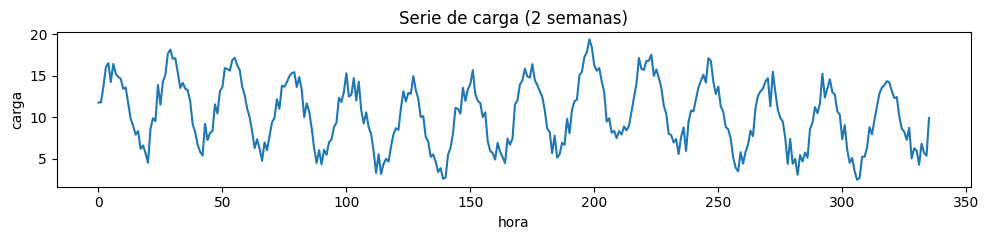

In [3]:
T=24*7*30                                  # ~30 semanas, resolución horaria
t=np.arange(T)
serie=(10 + 0.002*t
       + 5*np.sin(2*np.pi*t/24)             # ciclo diario
       + 2*np.sin(2*np.pi*t/168)            # ciclo semanal
       + 1.0*np.random.randn(T)).astype("float32")
mu,sd=serie.mean(),serie.std(); s=(serie-mu)/sd     # normalización
IN,OUT,STRIDE=120,24,3
X,Y=[],[]
for i in range(0,len(s)-IN-OUT,STRIDE):
    X.append(s[i:i+IN]); Y.append(s[i+IN:i+IN+OUT])
X=torch.tensor(np.array(X)).unsqueeze(-1); Y=torch.tensor(np.array(Y))  # (N,IN,1) , (N,OUT)
ntr=int(len(X)*0.8)
Xtr,Ytr,Xte,Yte=X[:ntr],Y[:ntr],X[ntr:],Y[ntr:]
print("Ventanas:",len(X)," | IN",IN,"OUT",OUT)
plt.figure(figsize=(10,2.5)); plt.plot(serie[:24*7*2]); plt.title("Serie de carga (2 semanas)")
plt.xlabel("hora"); plt.ylabel("carga"); plt.tight_layout(); plt.show()

## Modelo: encoder Transformer + cabeza de pronóstico

Proyectamos cada valor escalar a `d_model`, sumamos positional encoding, pasamos por el encoder y hacemos *pooling* temporal; una capa lineal predice las `OUT` horas futuras (pronóstico directo multi-horizonte).

In [4]:
class TSForecaster(nn.Module):
    def __init__(self, d=64, h=4, ff=128, nl=2, out=OUT):
        super().__init__()
        self.inp=nn.Linear(1,d); self.pe=PositionalEncoding(d,max_len=IN+8)
        self.enc=nn.ModuleList([EncoderLayer(d,h,ff) for _ in range(nl)]); self.head=nn.Linear(d,out)
    def forward(self, x, return_attn=False):
        h=self.pe(self.inp(x)); att=None
        for l in self.enc: h,att=l(h)
        y=self.head(h.mean(1))                 # pooling temporal → pronóstico
        return (y,att) if return_attn else y

model=TSForecaster().to(device)
print("Parámetros:", sum(p.numel() for p in model.parameters()))

Parámetros: 68632


## Entrenamiento (MSE) y comparación con baseline naïve

In [5]:
opt=torch.optim.Adam(model.parameters(),lr=1e-3); lf=nn.MSELoss()
Xtr_,Ytr_=Xtr.to(device),Ytr.to(device); t0=time.time()
for ep in range(12):
    model.train(); perm=torch.randperm(len(Xtr))
    for i in range(0,len(Xtr),128):
        idx=perm[i:i+128]; pred=model(Xtr_[idx]); loss=lf(pred,Ytr_[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    if (ep+1)%3==0: print(f"época {ep+1:2d}  train MSE {loss.item():.4f}")
model.eval()
with torch.no_grad(): pt=model(Xte.to(device)).cpu()
mse=((pt-Yte)**2).mean().item(); mae=(pt-Yte).abs().mean().item()
naive=Xte[:,-OUT:,0]; mse_n=((naive-Yte)**2).mean().item()   # repetir el último día
print(f"\nTransformer  MSE {mse:.4f}  MAE {mae:.4f}")
print(f"Baseline naïve MSE {mse_n:.4f}  →  el Transformer mejora ×{mse_n/mse:.1f}   ({time.time()-t0:.0f}s)")

época  3  train MSE 0.6885
época  6  train MSE 0.1607
época  9  train MSE 0.0618
época 12  train MSE 0.0583

Transformer  MSE 0.0869  MAE 0.2337
Baseline naïve MSE 0.1423  →  el Transformer mejora ×1.6   (56s)


## Pronóstico vs. real (una ventana de test)

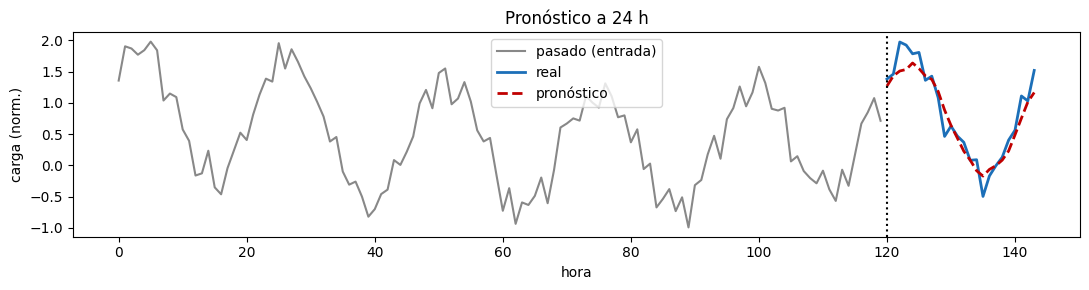

In [6]:
k=0
hist=Xte[k,:,0].numpy(); real=Yte[k].numpy(); prd=pt[k].numpy()
plt.figure(figsize=(11,3))
plt.plot(range(IN),hist,label="pasado (entrada)",color="#888")
plt.plot(range(IN,IN+OUT),real,label="real",color="#1C6FB8",lw=2)
plt.plot(range(IN,IN+OUT),prd,label="pronóstico",color="#C00000",lw=2,ls="--")
plt.axvline(IN,color="k",ls=":"); plt.legend(); plt.title("Pronóstico a 24 h")
plt.xlabel("hora"); plt.ylabel("carga (norm.)"); plt.tight_layout(); plt.show()

## Visualización: ¿a qué horas pasadas atiende el modelo?

Promediamos la self-attention del encoder sobre las queries: muestra qué posiciones de la ventana de entrada resultan más informativas (deberían resaltar los mismos instantes del ciclo diario/semanal).

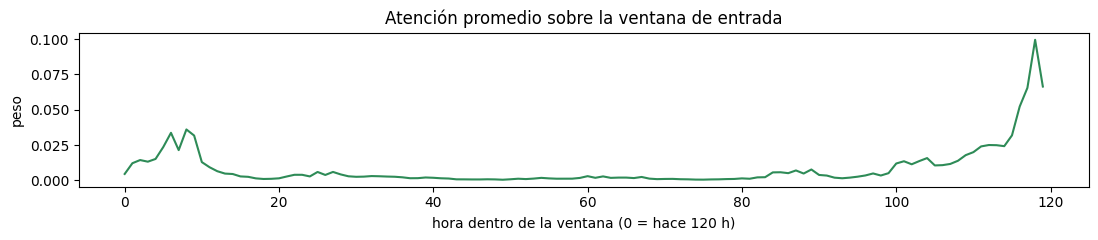

In [7]:
_,att=model(Xte[:1].to(device),return_attn=True)
imp=att[0].mean(0).mean(0).detach().cpu().numpy()    # importancia por posición de entrada
plt.figure(figsize=(11,2.5))
plt.plot(imp,color="#2E8B57"); plt.title("Atención promedio sobre la ventana de entrada")
plt.xlabel("hora dentro de la ventana (0 = hace %d h)"%IN); plt.ylabel("peso")
plt.tight_layout(); plt.show()

## Conclusión

El Transformer aprovecha la estacionalidad para pronosticar y **supera al baseline naïve**. Observe que para series continuas cambia el *embedding* (proyección lineal) pero la maquinaria de atención es la misma. Este ejercicio de series temporales sirve para ver la versatilidad de la arquitectura.
